In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score
import string
from nltk.corpus import stopwords
import re

#COLOCAR AQUI O CVS DE TRAINING
df_train = pd.read_csv('Data_Set/train.csv', header=0)
df_train = df_train.reset_index()  # make sure indexes pair with number of rows



df_test = pd.read_csv('Data_Set/test.csv', header=0)
df_test = df_test.reset_index()  # make sure indexes pair with number of rows


In [ ]:
#cleaning the data function ISTO DEMORA BUE

error_string = "service unavailable request due to maintenance downtime or capacity problems please try again later additionally service unavailable error was encountered while trying to use an errordocument to handle the request"

def clean_data(text,stops):
    text = text.lower()
    trans_table = str.maketrans({p: " " for p in string.punctuation})
    text = text.translate(trans_table)
    #precisamos de tirar dias da semana aqui-----------------------------------------------------------
    words = text.split()
    final = []
    for word in words:
         if word not in stops:
             final.append(word)
    final = " ".join(final)
    
    #forma exotica para remover pontuacao num texto
    #final = final.translate(str.maketrans("","",string.punctuation))
    
    # NOTA: caso os numeros nao tenham impacto na info dos textos
    # usamos isto para remover numeros (e talvez tenhamos de remover % tambem)
    # se os numeros forem importantes, talvez temos de modificar o texto de forma a indentificar os numeros
    # ex: 74,5% --> #PERCENT74,5
    
    final = "".join([i for i in final if not i.isdigit()])
    #forma NADA efeciente de tirar espaços
    while "  " in final:
        final = final.replace("  ", " ")
    return final

#the new data frame is going to have the same format but the text will be altered
def clean_dataframe(df):

    cleaned_dataframe = pd.DataFrame(columns=df.columns)
    base_weekdays = [
        "segunda-feira", "segundafeira", "segunda", "terça-feira", "terçafeira", "terça", "quarta-feira", "quartafeira", 
        "quarta", "quinta-feira", "quintafeira", "quinta", "sexta-feira",
        "sextafeira", "sexta", "sábado", "domingo"
    ]
    meses_pt = [
        "janeiro",
        "fevereiro",
        "marco",
        "março",    # caso queira considerar com acento também
        "abril",
        "maio",
        "junho",
        "julho",
        "agosto",
        "setembro",
        "outubro",
        "novembro",
        "dezembro"
    ]

    #ciclo iterrows
    stops = stopwords.words("portuguese")
    stops.extend(base_weekdays)
    stops.extend(meses_pt)

    #Ao inves de alterar o dataframe original, criamos um novo. Para evitar problemas de NONE e iterrows
    cleaned_rows = []
    for index, row in df.iterrows():
        #if the row is none , we delete it

        cleaned_row= clean_data(row['Text'],stops)
        
        #depois colocar isto antes do cleaned_row = clean_data(row['Text'],stops)
        if cleaned_row == "none" or cleaned_row == error_string:
            continue
        
        new_row = {}
        new_row['Label'] = row['Label']
        new_row['Text'] = cleaned_row
        cleaned_rows.append(new_row)

    cleaned_df = pd.DataFrame(cleaned_rows).reset_index(drop=True)
    return cleaned_df

df_train_cleaned = clean_dataframe(df_train)

df_test_cleaned = clean_dataframe(df_test)
    

In [ ]:
#Exemplo de data "limpa"
print(df_train_cleaned.at[32875,'Text'])

In [ ]:
# TF IDF podemos/devemos alterar o ngram_range e podemos colocar mais argumentos
vectorizer = TfidfVectorizer( lowercase=True,
                              max_features=5000,
                              max_df = 0.9,
                              min_df= 10,
                              ngram_range= (1,3),
                              stop_words = "english",
                              use_idf=True,
                              smooth_idf=True
                            )

training_vectors = vectorizer.fit_transform(df_train_cleaned['Text'])

testing_vectors = vectorizer.transform(df_test_cleaned['Text'])

feature_names = vectorizer.get_feature_names_out()

"""
dense = training_vectors.todense()
denselist = dense.tolist()

all_keywords = []

for description in denselist:
    x=0
    keywords = []
    for word in description:
        if word > 0:
            keywords.append(feature_names[x])
        x=x+1
    all_keywords.append(keywords)
 
print(all_keywords[0]) """

'\ndense = training_vectors.todense()\ndenselist = dense.tolist()\n\nall_keywords = []\n\nfor description in denselist:\n    x=0\n    keywords = []\n    for word in description:\n        if word > 0:\n            keywords.append(feature_names[x])\n        x=x+1\n    all_keywords.append(keywords)\n\nprint(all_keywords[0]) '

In [ ]:
def print_tfidf_summary(vectors):
    n_docs, n_feats = vectors.shape
    nnz = vectors.nnz
    density = nnz / (n_docs * n_feats)
    print(f"shape: {n_docs} x {n_feats}")
    print(f"non-zeros: {nnz}  density: {density:.4%}")

def top_features_for_doc(vectors, feature_names, doc_idx=0, top_n=10):
    row = vectors.getrow(doc_idx).tocoo()
    if row.nnz == 0:
        print(f"doc {doc_idx}: no non-zero features")
        return
    idx = np.argsort(row.data)[::-1][:top_n]
    terms = [feature_names[row.col[i]] for i in idx]
    scores = row.data[idx]
    print(f"Top {top_n} features for doc {doc_idx}:")
    for t, s in zip(terms, scores):
        print(f"  {t}: {s:.4f}")

def top_features_global(vectors, feature_names, top_n=30, by="mean"):
    # by="mean" or "sum"
    if by == "mean":
        vals = np.asarray(vectors.mean(axis=0)).ravel()
    else:
        vals = np.asarray(vectors.sum(axis=0)).ravel()
    top_idx = np.argsort(vals)[::-1][:top_n]
    print(f"Top {top_n} features by {by}:")
    for i in top_idx:
        print(f"  {feature_names[i]}: {vals[i]:.6f}")

def as_dataframe(vectors, feature_names, max_cells=1e9):
    # Convert only if not too large
    n_docs, n_feats = vectors.shape
    if n_docs * n_feats > max_cells:
        raise MemoryError("matrix too large to convert to dense DataFrame")
    return pd.DataFrame(vectors.toarray(), columns=feature_names)


shape: 50587 x 5000
non-zeros: 5117757  density: 2.0233%
Top 15 features for doc 0:
  operação: 0.3798
  pj: 0.3423
  droga: 0.2618
  movimentos: 0.2600
  tráfico: 0.2437
  iii: 0.1921
  inspeção: 0.1802
  realizadas: 0.1657
  busca: 0.1608
  feitas: 0.1410
  ações: 0.1404
  combate: 0.1323
  oito: 0.1265
  internacional: 0.1173
  comunicado: 0.1073
Top 40 features by mean:
  anos: 0.021349
  euros: 0.020604
  portugal: 0.017526
  milhões: 0.016776
  governo: 0.016358
  pessoas: 0.016080
  ter: 0.015572
  ainda: 0.014918
  sobre: 0.014814
  presidente: 0.014687
  feira: 0.014302
  mil: 0.013462
  ano: 0.013393
  dia: 0.013135
  estado: 0.013133
  vai: 0.012926
  ministro: 0.012743
  país: 0.012492
  saúde: 0.012391
  todos: 0.011907
  pode: 0.011694
  costa: 0.011646
  disse: 0.011012
  milhões euros: 0.010971
  lisboa: 0.010953
  segundo: 0.010774
  fazer: 0.010539
  primeiro: 0.010513
  dois: 0.010373
  onde: 0.010306
  porque: 0.010251
  contra: 0.010167
  vida: 0.010021
  agora: 0.

In [ ]:
# usage examples
print_tfidf_summary(training_vectors)
top_features_for_doc(training_vectors, feature_names, doc_idx=0, top_n=15)
top_features_global(training_vectors, feature_names, top_n=40, by="mean")

In [ ]:
# --- Corpus-level term summary and prints ---
# compute sums, means and document frequencies for each feature
sums = np.asarray(training_vectors.sum(axis=0)).ravel()
means = np.asarray(training_vectors.mean(axis=0)).ravel()
df_counts = np.diff(training_vectors.tocsc().indptr)  # documents-per-term

summary = pd.DataFrame({
    'term': feature_names,
    'sum': sums,
    'mean': means,
    'df': df_counts
})
if hasattr(vectorizer, 'idf_'):
    summary['idf'] = vectorizer.idf_

# print top terms by different metrics
def print_top_terms(summary, by='sum', top_n=30):
    print(f"\nTop {top_n} terms by {by}:")
    top = summary.sort_values(by=by, ascending=False).head(top_n)
    print(top[['term', 'sum', 'mean', 'df'] + (['idf'] if 'idf' in top.columns else [])].to_string(index=False))




Top 30 terms by sum:
         term         sum     mean    df      idf
         anos 1079.977144 0.021349 18308 2.016322
        euros 1042.315111 0.020604 10512 2.571102
     portugal  886.586389 0.017526 12456 2.401432
      milhões  848.660327 0.016776  8676 2.763039
      governo  827.500813 0.016358 11507 2.480672
      pessoas  813.446800 0.016080 13707 2.305735
          ter  787.727472 0.015572 18514 2.005133
        ainda  754.667592 0.014918 19825 1.936720
        sobre  749.419956 0.014814 16146 2.141980
   presidente  742.985711 0.014687 11163 2.511020
        feira  723.511841 0.014302 16647 2.111424
          mil  681.001487 0.013462  8739 2.755804
          ano  677.535234 0.013393 12877 2.368194
          dia  664.469704 0.013135 11845 2.451724
       estado  664.349222 0.013133 11554 2.476596
          vai  653.870950 0.012926 12524 2.395988
     ministro  644.618213 0.012743  7835 2.864986
         país  631.925458 0.012492 11470 2.483892
        saúde  626.818598 0.

In [ ]:
print_top_terms(summary, by='sum', top_n=30)
print_top_terms(summary, by='df', top_n=30)

# show sample cleaned texts for first 5 documents
#print('\nSample cleaned texts (first 5 rows):')
#for i in range(min(5, len(df_train))):
    #print(f"[{i}] ", df_train['Text'].iloc[i])

In [ ]:
# save summary CSV
summary_out = 'tfidf_term_summary.csv'
summary.sort_values(by='sum', ascending=False).to_csv(summary_out, index=False)
print(f"\nSaved term summary to: {summary_out}")

In [ ]:
import os
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
import joblib
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

# X é do training
X = training_vectors  # sparse TF-IDF matrix 
y = df_train_cleaned['Label'].values  

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = 'f1_macro'
results_dir = 'cv_results'
os.makedirs(results_dir, exist_ok=True)

In [11]:
models = {
    'decision_tree': {
        'pipeline': Pipeline([('clf', DecisionTreeClassifier(random_state=42))]),
        'params': {
            'clf__criterion': ['gini', 'entropy'],
            'clf__max_depth': [None, 10, 20],
            'clf__min_samples_leaf': [1, 2, 5]
        }
    },
    'gaussian_nb': {
        # use SVD to reduce dimensionality and produce dense input for GaussianNB
        'pipeline': Pipeline([('svd', TruncatedSVD(n_components=200, random_state=42)),
                              ('clf', GaussianNB())]),
        'params': {
            'svd__n_components': [100, 200],
            'clf__var_smoothing': [1e-9, 1e-8]
        }
    },
    'logreg_l2': {
        'pipeline': Pipeline([('clf', LogisticRegression(penalty='l2', solver='saga', max_iter=2000, random_state=42))]),
        'params': {
            'clf__C': [0.01, 0.1, 1, 10],
            'clf__class_weight': [None, 'balanced']
        }
    },
    'logreg_l1': {
        'pipeline': Pipeline([('clf', LogisticRegression(penalty='l1', solver='saga', max_iter=2000, random_state=42))]),
        'params': {
            'clf__C': [0.01, 0.1, 1, 10],
            'clf__class_weight': [None, 'balanced']
        }
    },
    'mlp': {
        # SVD -> scaler -> MLP
        'pipeline': Pipeline([
            ('svd', TruncatedSVD(n_components=200, random_state=42)),
            ('scaler', StandardScaler()),
            ('clf', MLPClassifier(max_iter=800, random_state=42))
        ]),
        'params': {
            'svd__n_components': [100, 200],
            'clf__hidden_layer_sizes': [(50,), (100,), (50, 25), (100, 50)],
            'clf__alpha': [1e-4, 1e-3],
            'clf__learning_rate_init': [1e-3],
            'clf__activation': ['relu']
        }
    }
}

In [12]:
# Run grid searches
for name, spec in models.items():
    print(f"\n=== GridSearchCV: {name} ===")
    gs = GridSearchCV(spec['pipeline'], spec['params'],
                      cv=cv, scoring=scoring, n_jobs=-1, verbose=0, refit=True)
    gs.fit(X, y)
    print("best params:", gs.best_params_)
    # cross-validated predictions using the best estimator
    y_pred = cross_val_predict(gs.best_estimator_, X, y, cv=cv, n_jobs=-1)
    print("classification report (cv):")
    print(classification_report(y, y_pred, digits=4))
    # save results
    pd.DataFrame(gs.cv_results_).to_csv(os.path.join(results_dir, f"{name}_cv_results.csv"), index=False)
    joblib.dump(gs.best_estimator_, os.path.join(results_dir, f"{name}_best_estimator.joblib"))
    print(f"Saved cv_results and best_estimator for {name} in {results_dir}")

print("\nAll searches complete. Results directory:", results_dir)


=== GridSearchCV: decision_tree ===


best params: {'clf__criterion': 'gini', 'clf__max_depth': None, 'clf__min_samples_leaf': 2}
classification report (cv):
              precision    recall  f1-score   support

           0     0.8121    0.8513    0.8312     25209
           1     0.8448    0.8043    0.8241     25378

    accuracy                         0.8277     50587
   macro avg     0.8285    0.8278    0.8276     50587
weighted avg     0.8285    0.8277    0.8276     50587

Saved cv_results and best_estimator for decision_tree in cv_results

=== GridSearchCV: gaussian_nb ===
best params: {'clf__var_smoothing': 1e-09, 'svd__n_components': 200}
classification report (cv):
              precision    recall  f1-score   support

           0     0.7849    0.6539    0.7134     25209
           1     0.7051    0.8220    0.7591     25378

    accuracy                         0.7382     50587
   macro avg     0.7450    0.7379    0.7362     50587
weighted avg     0.7449    0.7382    0.7363     50587

Saved cv_results and best_

KeyboardInterrupt: 

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
from sklearn.preprocessing import label_binarize

RESULTS_DIR = "cv_results"
# COLOCAR AQUI O CVS DE VALIDACAO
DATA_CSV = "Data_Set/val.csv"
X_SPARSE_PATH = os.path.join(RESULTS_DIR, "X_sparse.joblib")
VEC_PATH = "tfidf_vectorizer.joblib"
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
OUT_METRICS = os.path.join(RESULTS_DIR, "metrics_comparison.csv")
OUT_ROC = os.path.join(RESULTS_DIR, "best_model_roc.png")

def load_features(texts):
    """
    texts: pd.Series or list-like of texts for which we need features.
    If a saved X_sparse.joblib exists, reuse it only if row counts match.
    Otherwise transform texts with the saved vectorizer (VEC_PATH).
    """
    if os.path.exists(X_SPARSE_PATH):
        X = joblib.load(X_SPARSE_PATH)
        if X.shape[0] == len(texts):
            print(f"Loaded X sparse from {X_SPARSE_PATH} (rows match: {X.shape[0]})")
            return X
        else:
            print(f"Saved X_sparse has {X.shape[0]} rows but {len(texts)} requested — rebuilding from vectorizer.")
    if os.path.exists(VEC_PATH):
        vec = joblib.load(VEC_PATH)
        X = vec.transform(pd.Series(texts).fillna('').astype(str))
        print(f"Transformed texts with loaded vectorizer {VEC_PATH}")
        return X
    raise FileNotFoundError("No X_sparse.joblib or tfidf_vectorizer.joblib found; run cv_search first.")

def load_data():
    df = pd.read_csv(DATA_CSV)
    if 'Label' not in df.columns:
        raise RuntimeError("CSV must contain 'Label' column")
    y = df['Label'].values
    return df, y

def load_estimators():
    files = [f for f in os.listdir(RESULTS_DIR) if f.endswith("_best_estimator.joblib")]
    files.sort()
    if not files:
        raise RuntimeError(f"No *_best_estimator.joblib files found in {RESULTS_DIR}")
    estimators = {}
    for f in files:
        name = f.replace("_best_estimator.joblib", "")
        estimators[name] = joblib.load(os.path.join(RESULTS_DIR, f))
    return estimators

def try_get_scores(est, X, y):
    # attempt predict_proba then decision_function; return None if not available
    try:
        probs = cross_val_predict(est, X, y, cv=CV, method='predict_proba', n_jobs=-1)
        return probs
    except Exception:
        try:
            scores = cross_val_predict(est, X, y, cv=CV, method='decision_function', n_jobs=-1)
            return scores
        except Exception:
            return None

def compute_metrics(estimators, X, y):
    rows = []
    scores_cache = {}
    for name, est in estimators.items():
        print(f"Evaluating: {name}")
        y_pred = cross_val_predict(est, X, y, cv=CV, n_jobs=-1)
        acc = accuracy_score(y, y_pred)
        prec = precision_score(y, y_pred, average='macro', zero_division=0)
        rec = recall_score(y, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y, y_pred, average='macro', zero_division=0)
        rows.append({
            'model': name,
            'accuracy': acc,
            'precision_macro': prec,
            'recall_macro': rec,
            'f1_macro': f1
        })
        scores = try_get_scores(est, X, y)
        if scores is not None:
            scores_cache[name] = scores
    dfm = pd.DataFrame(rows).sort_values(by='f1_macro', ascending=False).reset_index(drop=True)
    dfm.to_csv(OUT_METRICS, index=False)
    print(f"\nSaved metrics table to {OUT_METRICS}\n")
    print(dfm.to_string(index=False, float_format="%.4f"))
    return dfm, scores_cache

def plot_roc_for_best(dfm, scores_cache, y):
    best_name = dfm.loc[0, 'model']
    print(f"\nBest model by f1_macro: {best_name}")
    if best_name not in scores_cache:
        print("No probability/score available for best model; cannot plot ROC/AUC.")
        return
    y_score = scores_cache[best_name]
    classes = np.unique(y)
    n_classes = len(classes)
    plt.figure(figsize=(8,6))
    if n_classes == 2:
        # binary: ensure shape and get positive-class scores
        if y_score.ndim == 2 and y_score.shape[1] >= 2:
            prob_pos = y_score[:,1]
        else:
            prob_pos = y_score.ravel()
        fpr, tpr, _ = roc_curve(y, prob_pos, pos_label=classes[-1])
        auc_val = roc_auc_score(y, prob_pos)
        plt.plot(fpr, tpr, label=f'{best_name} (AUC = {auc_val:.4f})', lw=2)
    else:
        # multiclass: one-vs-rest per-class curves + macro AUC
        y_bin = label_binarize(y, classes=classes)
        aucs = []
        for i, cls in enumerate(classes):
            if y_score.ndim == 2 and y_score.shape[1] == n_classes:
                score_i = y_score[:, i]
            else:
                score_i = y_score.ravel()
            fpr, tpr, _ = roc_curve(y_bin[:, i], score_i)
            auc_i = roc_auc_score(y_bin[:, i], score_i)
            aucs.append(auc_i)
            plt.plot(fpr, tpr, lw=1, label=f'class {cls} (AUC={auc_i:.3f})')
        try:
            macro_auc = roc_auc_score(y_bin, y_score, average='macro', multi_class='ovr')
        except Exception:
            macro_auc = np.mean(aucs)
        plt.plot([], [], ' ', label=f'macro AUC = {macro_auc:.4f}')
    

In [ ]:
plt.plot([0,1], [0,1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC curve — logreg_l12')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(OUT_ROC)
print(f"Saved ROC plot to {OUT_ROC}")
plt.show()

In [ ]:
#2 a) 
def get_top_features(model, X, feature_names, top_n=10):
    if not hasattr(model, 'coef_'):
        print("Model does not have coef_ attribute; cannot extract feature importances.")
        return
    coefs = model.coef_.ravel() #.ravel() para transformar numa array 1D porque a classificaçao é binaria
    sorted_idx = np.argsort(coefs)
    top_positive_idx = sorted_idx[-top_n:][::-1]
    print(f"\nTop {top_n} real news words by absolute coefficient value:")
    for idx in top_positive_idx:
        print(f"  {feature_names[idx]}: {coefs[idx]:.6f}") 

    print(f"\nTop {top_n} real news words:")
    top_negative_idx = sorted_idx[:top_n]
    for idx in top_negative_idx:
        print(f"  {feature_names[idx]}: {coefs[idx]:.6f}")


In [ ]:

# b)
#Colocar na resposta os valores de non-zero features e corrigir esta resposta
"""How many features have non-zero weights in each?

L1 regularization (Lasso) produces sparse models: many coefficients are exactly zero.
L2 regularization (Ridge) produces dense models: most coefficients are non-zero (but may be small).
What does this tell you about feature selection?

L1 regularization selects features by setting many weights to zero, automatically choosing a subset of important words.
L2 regularization shrinks all weights but does not remove features.
When would you prefer L1 vs L2 for text classification?

L1: When you want automatic feature selection, a simpler model, or interpretability (see which words matter).
L2: When you expect many features to contribute a little, or want to avoid overfitting without removing features.
Summary:

L1 = feature selection, sparse model.
L2 = all features used, less interpretability.
Prefer L1 for high-dimensional, sparse data (like text) and interpretability; L2 for stability and when all features may matter."""

def get_nonzero_features(model):
    if not hasattr(model, 'coef_'):
        print("Model does not have coef_ attribute; cannot extract feature importances.")
        return
    coefs = model.coef_.ravel()
    nonzero_count = np.sum(coefs != 0)
    print(f"Number of non-zero features: {nonzero_count}")
    return nonzero_count

In [ ]:

# c) and d) VER IMPORTS DEPOIS
def explain_with_lime_randomsamples(c,explainer, df, num_samples=1000):
    from numpy import argmax

    if num_samples == 0:
        return
    
    random_idxs = np.random.choice(len(df), size=num_samples, replace=False)

    correct_classifications = 0
    total_classifications = 0

    for idx in random_idxs:
        if argmax(c.predict_proba([df.iloc[idx]])) == df.loc[idx, 'Label']:
            correct_classifications += 1
        total_classifications += 1

    accuracy = correct_classifications / total_classifications
    print(f"\nLIME-based classification accuracy over {num_samples} random samples: {accuracy}")

def explain_with_lime(model, vectorizer, df, idxs, num_samples=0):
    
    from lime import lime_text
    from sklearn.pipeline import make_pipeline
    from lime.lime_text import LimeTextExplainer

    c = make_pipeline(vectorizer, model)
    class_names = ['fake', 'real']

    #por enquanto so a explicar o primeiro
    print(c.predict_proba([df.iloc[idxs[0]]]))
    
    explainer = LimeTextExplainer(class_names=class_names)
    
    for idx in idxs:
        #este exp é so para mostrar o resultado em as_list
        exp = explainer.explain_instance(df.iloc[idx], 
                                         c.predict_proba, 
                                         num_features=10) #number of features to show in explanation, we can change it
        print(f"\nLIME explanation for document index {idx}:")
        print(f"Probabilities of being fake and real: {c.predict_proba([df.iloc[idx]])}")
        
        print(f"True label: {df.loc[idx, 'Label']}")

        exp.as_list()


    explain_with_lime_randomsamples(c, vectorizer, df,explainer ,num_samples)
    



Cluster 0 closest documents:
 Document index: 39852, Distance: 0.8654
 Text: maioria conselheiros defende remodelação presidente marcelo anunciou convocação conselho estado final altura chamará belém partidos maioria conselheiros estado pronunciou sobre atual situação política posição dominante deveria ‘refrescamento’ governo devendo antónio costa substituir ministros contestados procurar personalidades maturidade experiência políticas menos cenário eleições antecipadas parece afastado augusto santos silva presidente assembleia república presidente assembleia república augusto santos silva considera «um erro» dissolver assembleia república sabor sondagens resultados eleitorais «de ordem» designadamente europeias podcast grupo parlamentar ps augusto santos silva defendeu antónio costa «tem todas condições» levar legislatura fim durante sessão solene santos silva alertado princípio cumprimento mandatos salientando tempo cada instituição deve respeitado «sem atropelos precipitações» antó

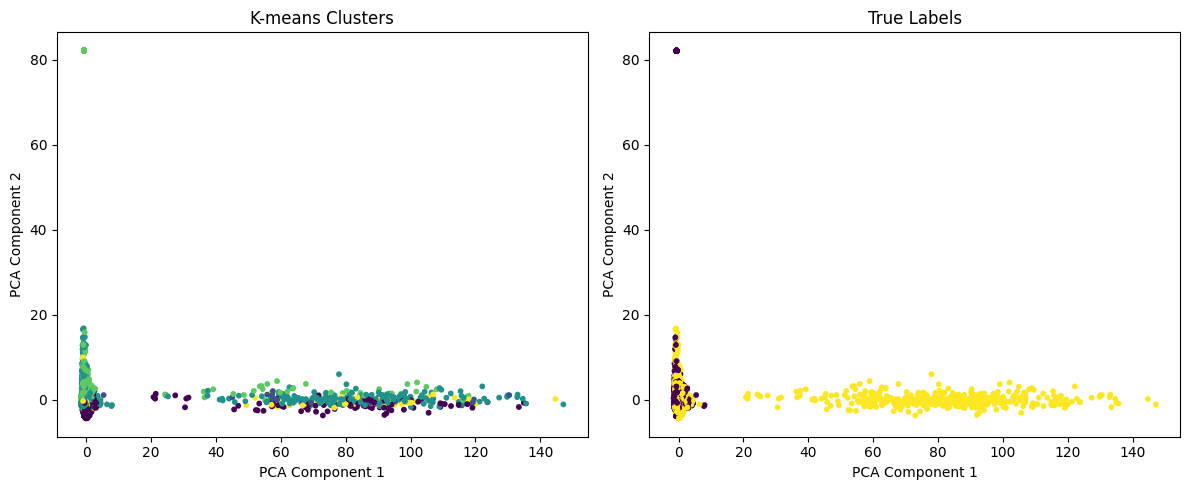

In [ ]:

import sklearn.cluster as clustering
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def kmeans(k=5,n_init=10):

    #a) apply k-means to the training data with k=5 clusters
    kmeans_model = clustering.KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=n_init)

    #apply model to training data
    kmeans_model.fit(training_vectors)
    
    order_centroids = kmeans_model.cluster_centers_.argsort()[:, ::-1]

    #talvez possamos reusar a feature names 
    terms = vectorizer.get_feature_names_out()

    with open("kmeans_clusters.txt", "w", encoding="utf-8") as f:
        for i in range(k):
            f.write(f"Cluster {i}:\n")
            for ind in order_centroids[i, :10]:  # top 10 terms per cluster
                f.write(f" {terms[ind]}\n")
            f.write("\n")

    #b) Inspect 3 documents closest to each centroid, and afterwards, assign semantic labels to each cluster 

    distances = kmeans_model.transform(training_vectors)

    for i in range(k):
        assigned_idxs = np.where(kmeans_model.labels_ == i)[0]
        closest_idxs = assigned_idxs[np.argsort(distances[assigned_idxs, i])[:3]]
        print(f"\nCluster {i} closest documents:")
        for idx in closest_idxs:
            print(f" Document index: {idx}, Distance: {distances[idx, i]:.4f}")
            print(f" Text: {df_train_cleaned.iloc[idx]['Text']}\n")
            #falta aqui colocar a label

    #c) Visualize clusters in 2D using PCA. Create two plots: one colored by cluster assignment, one by true label.
    
    X = training_vectors.toarray()
    y = df_train_cleaned['Label'].values

    #Standardize the data before PCA
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    #Não sei se o X_scaled está bem, o gráfico fica mesmo estranho
    
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_model.labels_, cmap='viridis', s=10)
    plt.title('K-means Clusters')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.subplot(1, 2, 2)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_train_cleaned['Label'], cmap='viridis', s=10)
    plt.title('True Labels')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.tight_layout()
    plt.show()
    





Cluster 0 closest documents:
 Document index: 7145, Distance: 0.8060
 Text:  milhões euros fogem offshores

 Document index: 4527, Distance: 0.8101
 Text: economia portuguesa passa défice excedente externo milhões regulador afirma aumento exportações reflete sobretudo contributo viagens turismo cujas exportações cresceram termos homólogos economia portuguesa registou excedente externo milhões euros primeiro trimestre compara défice milhões euros período ano passado dados revelados banco portugal revelam apenas saldo balanças corrente capital milhões euros significa milhões euros face mês segundo banco central balança bens serviços tornou excedentária tendo registado saldo milhões euros contribuiu redução milhões euros défice balança bens milhões euros devido crescimento exportações milhões euros superior importações milhões euros respetivamente assim aumento excedente balança serviços milhões euros milhões euros aumento exportações importações serviços respetivamente regulador afirma 

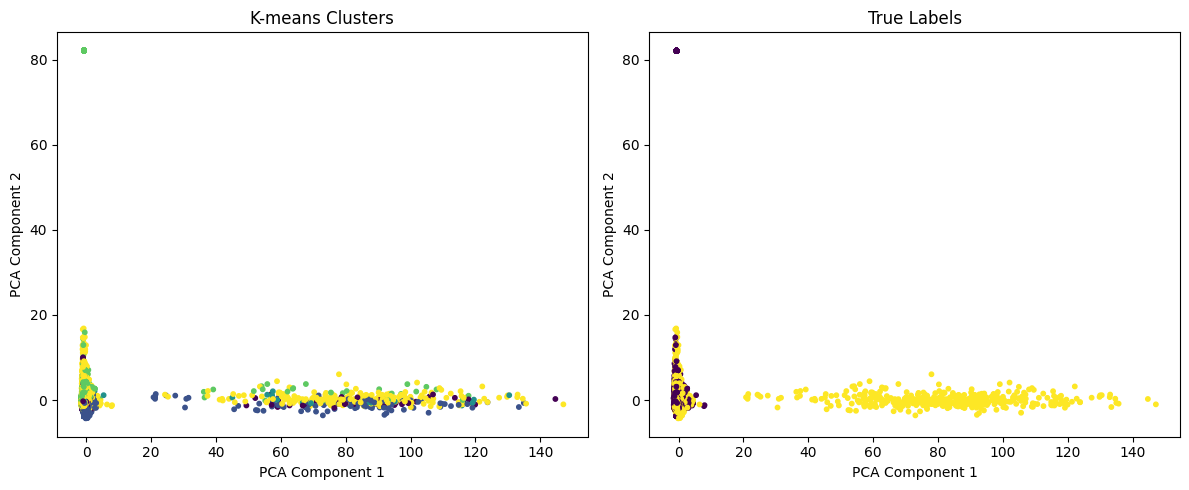

In [ ]:
def main():
    #Exercise 1
    os.makedirs(RESULTS_DIR, exist_ok=True)
    df, y = load_data()
    # ensure we have the vectorizer and feature names available for downstream steps
    if os.path.exists(VEC_PATH):
        vectorizer = joblib.load(VEC_PATH)
        feature_names = vectorizer.get_feature_names_out()
    else:
        raise FileNotFoundError("tfidf_vectorizer.joblib not found; run the TF-IDF step first.")
    # pass current dataframe texts so load_features can validate or rebuild X
    X = load_features(df['Text'])
    estimators = load_estimators()
    dfm, scores_cache = compute_metrics(estimators, X, y)
    plot_roc_for_best(dfm, scores_cache, y)

    #Exercise 2
    # Path to your saved best estimator (adjust name if needed) ASSUMO L2 LOGREG
    best_model_path = "cv_results/logreg_l2_best_estimator.joblib"

    # a)
    best_model = joblib.load(best_model_path)
    get_top_features(best_model, X, feature_names, top_n=10)
    
    #b)
    model_l2_path = "cv_results/logreg_l2_best_estimator.joblib"
    model_l1_path = "cv_results/logreg_l1_best_estimator.joblib"
    model_l2 = joblib.load(model_l2_path)
    model_l1 = joblib.load(model_l1_path)

    get_nonzero_features(model_l2)
    get_nonzero_features(model_l1)

    #c)
    idxs = [2921, 2437, 5557, 1697]
    explain_with_lime(best_model, vectorizer, df, idxs)

    #d)
    idxs = [2921, 2437, 5557, 1697]
    model_mlp_path = "cv_results/mlp_best_estimator.joblib"
    model_mlp = joblib.load(model_mlp_path)
    explain_with_lime(model_mlp, vectorizer, df, idxs)

    #Exercise 3

    kmeans()


if __name__ == "__main__":
    main()